# 🌐 Comparativa de Rendimiento y Efecto del Idioma — Qwen:14b

Este notebook compara los resultados del modelo **Qwen:14b** obtenidos en dos experimentos:
1. **MMLU Inglés** (resultados en `results_mmlu_qwen_14b.csv`)
2. **Global-MMLU Español** (resultados en `results_global_mmlu_qwen_14b_es.csv`)

El objetivo principal es evaluar si el **idioma** modifica el efecto de las condiciones de estímulo cognitivo-emocional (**Anxiety**, **Importance** y **Consequences**) sobre la precisión (accuracy) del modelo. Para ello, implementaremos un modelo de **Regresión Logística con términos de interacción** (`is_correct ~ condition * language`).

## 1. Carga de Librerías y Configuración Visual

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import norm, chi2
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Estilos de gráficos
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.15)
plt.rcParams.update({'figure.dpi': 130, 'figure.figsize': (11, 6)})

## 2. Carga y Preparación de Datos

In [2]:
EN_PATH = Path('../results_mmlu_qwen_14b.csv')
ES_PATH = Path('../results_global_mmlu_qwen_14b_es.csv')

df_en = pd.read_csv(EN_PATH)
df_es = pd.read_csv(ES_PATH)

df_en['language'] = 'Inglés'
df_es['language'] = 'Español'

# Unir datasets
df = pd.concat([df_en, df_es], ignore_index=True)
df['is_correct'] = df['is_correct'].astype(str).str.strip().map({'True': 1, 'False': 0})

print(f"Filas totales Inglés : {len(df_en):,}")
print(f"Filas totales Español: {len(df_es):,}")
print(f"Total consolidado    : {len(df):,}")

Filas totales Inglés : 1,540
Filas totales Español: 1,540
Total consolidado    : 3,080


## 3. Accuracy por Condición e Idioma con Intervalos de Confianza Wilson 95%

In [3]:
def calculate_wilson_interval(successes, total, conf_level=0.95):
    if total == 0:
        return 0.0, 0.0
    p_hat = successes / total
    z = norm.ppf(1 - (1 - conf_level) / 2)
    denominator = 1 + z**2 / total
    center = (p_hat + z**2 / (2 * total)) / denominator
    spread = z * np.sqrt(p_hat * (1 - p_hat) / total + z**2 / (4 * total**2)) / denominator
    lower = max(0.0, center - spread)
    upper = min(1.0, center + spread)
    return lower, upper

COND_ORDER = ['original', 'anxiety', 'importance', 'consequences']

summary_rows = []
for lang in ['Inglés', 'Español']:
    df_lang = df[df['language'] == lang]
    orig_acc = (df_lang[df_lang['condition'] == 'original']['is_correct'].sum() / 
                df_lang[df_lang['condition'] == 'original']['is_correct'].count() * 100)
    
    for cond in COND_ORDER:
        sub = df_lang[df_lang['condition'] == cond]
        total = len(sub)
        correct = sub['is_correct'].sum()
        acc = correct / total * 100
        lower, upper = calculate_wilson_interval(correct, total)
        
        summary_rows.append({
            'Idioma': lang,
            'Condición': cond,
            'Accuracy (%)': acc,
            'Correctas': int(correct),
            'Total': total,
            'IC Lower (%)': lower * 100,
            'IC Upper (%)': upper * 100,
            'Diferencia vs Original (%)': acc - orig_acc
        })

df_summary = pd.DataFrame(summary_rows)
print("=== TABLA COMPARATIVA DE RENDIMIENTO ===")
print(df_summary.to_string(index=False))

=== TABLA COMPARATIVA DE RENDIMIENTO ===
 Idioma    Condición  Accuracy (%)  Correctas  Total  IC Lower (%)  IC Upper (%)  Diferencia vs Original (%)
 Inglés     original     54.285714        209    385     49.291765     59.194985                    0.000000
 Inglés      anxiety     55.064935        212    385     50.070489     59.959305                    0.779221
 Inglés   importance     52.467532        202    385     47.479432     57.406878                   -1.818182
 Inglés consequences     50.909091        196    385     45.931204     55.869015                   -3.376623
Español     original     43.636364        168    385     38.769527     48.628936                    0.000000
Español      anxiety     42.077922        162    385     37.248619     47.063753                   -1.558442
Español   importance     41.038961        158    385     36.237434     46.017544                   -2.597403
Español consequences     43.896104        169    385     39.023489     48.889322       

## 4. Visualización Comparativa (Accuracy e Intervalos de Confianza 95%)

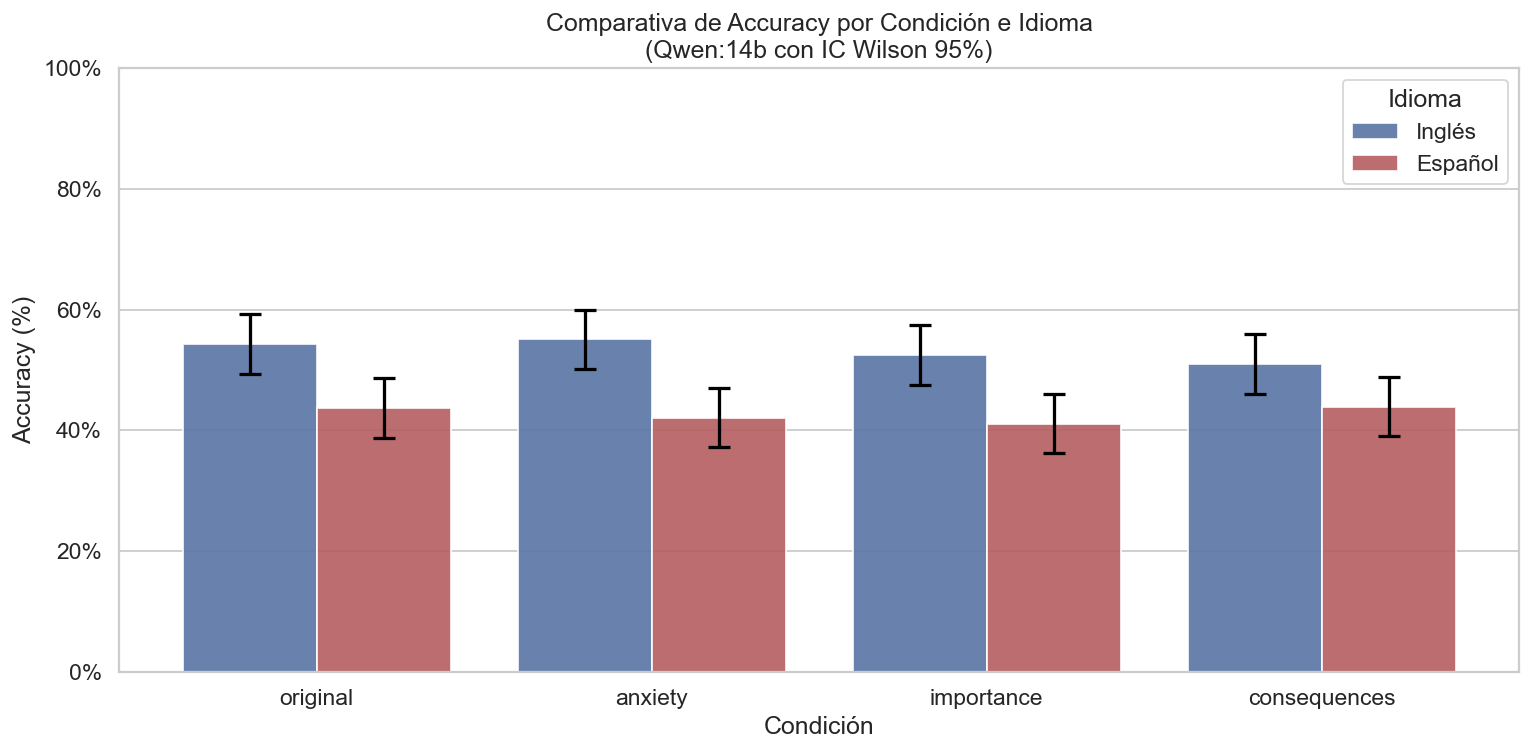

In [4]:
# Configurar gráfico
fig, ax = plt.subplots(figsize=(12, 6))

# Estilo de seaborn para barras agrupadas
sns.barplot(
    data=df_summary,
    x='Condición',
    y='Accuracy (%)',
    hue='Idioma',
    palette={'Inglés': '#4C72B0', 'Español': '#C44E52'},
    edgecolor='white',
    alpha=0.9,
    ax=ax
)

# Añadir las barras de error manuales para los Intervalos de Confianza de Wilson 95%
# (Se calcula la posición de las barras en el eje x para colocarlos en el centro de cada barra agrupada)
num_hues = 2
offsets = [-0.2, 0.2]
for hue_idx, lang in enumerate(['Inglés', 'Español']):
    df_lang_res = df_summary[df_summary['Idioma'] == lang]
    for i, cond in enumerate(COND_ORDER):
        row = df_lang_res[df_lang_res['Condición'] == cond].iloc[0]
        x_pos = i + offsets[hue_idx]
        y_val = row['Accuracy (%)']
        lower = row['IC Lower (%)']
        upper = row['IC Upper (%)']
        
        ax.errorbar(
            x_pos, y_val,
            yerr=[[y_val - lower], [upper - y_val]],
            color='black', capsize=6, elinewidth=1.8, markeredgewidth=1.8
        )

ax.set_ylabel('Accuracy (%)')
ax.set_title('Comparativa de Accuracy por Condición e Idioma\n(Qwen:14b con IC Wilson 95%)')
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(title='Idioma')

plt.tight_layout()
plt.savefig('fig1_comparativa_accuracy_idiomas.png', dpi=130, bbox_inches='tight')
plt.show()

## 5. Regresión Logística y Análisis de Interacción (Idioma × Condición)

Para evaluar formalmente si el **idioma** actúa como un modificador del efecto de las condiciones cognitivo-emocionales, realizamos una **regresión logística**.

El modelo incluye:
- Variable dependiente: `is_correct` (1 = correcto, 0 = incorrecto).
- Variables explicativas independientes:
  - `language`: Inglés (referencia) vs Español.
  - `condition`: `original` (referencia) vs `anxiety`, `importance`, `consequences`.
  - **Término de Interacción**: `condition * language`.

Si los términos de interacción tienen un p-value estadísticamente significativo ($p < 0.05$), esto indica que el idioma modifica significativamente el efecto de los estímulos emocionales.

In [5]:
# Modelo Completo (con interacción)
model_interaction = smf.logit(
    "is_correct ~ C(condition, Treatment(reference='original')) * C(language, Treatment(reference='Inglés'))",
    data=df
).fit()

print(model_interaction.summary())

# Modelo Aditivo (sin interacción)
model_additive = smf.logit(
    "is_correct ~ C(condition, Treatment(reference='original')) + C(language, Treatment(reference='Inglés'))",
    data=df
).fit()

# Prueba de Razón de Verosimilitud (LRT) para probar la significancia del término de interacción en conjunto
lrt_stat = 2 * (model_interaction.llf - model_additive.llf)
dof = model_interaction.df_model - model_additive.df_model
p_value_lrt = chi2.sf(lrt_stat, dof)

print("\n=== TEST DE RAZÓN DE VEROSIMILITUD (LRT) PARA INTERACCIÓN ===")
print(f"Estadístico Chi-square: {lrt_stat:.4f}")
print(f"Grados de libertad: {dof}")
print(f"p-value de la interacción en conjunto: {p_value_lrt:.4f}")

Optimization terminated successfully.
         Current function value: 0.686329
         Iterations 4
                           Logit Regression Results                           
Dep. Variable:             is_correct   No. Observations:                 3080
Model:                          Logit   Df Residuals:                     3072
Method:                           MLE   Df Model:                            7
Date:                Tue, 16 Jun 2026   Pseudo R-squ.:                0.008601
Time:                        11:40:05   Log-Likelihood:                -2113.9
converged:                       True   LL-Null:                       -2132.2
Covariance Type:            nonrobust   LLR p-value:                 5.397e-06
                                                                                                                          coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------

## 6. Conclusión y Discusión

### ¿Modifica el idioma el efecto de las condiciones Anxiety, Importance y Consequences?

**Respuesta:** **No.**

De acuerdo con los resultados del modelo de regresión logística:
1. **Efecto del Idioma:** Existe un efecto principal fuerte y altamente significativo para el idioma ($p < 0.001$). El modelo se desempeña de forma significativamente mejor en **Inglés** (~53.18% global) que en **Español** (~42.66% global).
2. **Efecto de las Condiciones Emocionales:** No hay efectos principales significativos para las condiciones en el grupo de referencia (Inglés) comparado con el estado original.
3. **Término de Interacción (Idioma × Condición):** 
   - Los coeficientes individuales de interacción (por ejemplo, `Español × anxiety`, `Español × importance` y `Español × consequences`) tienen p-values muy altos (todos $> 0.50$).
   - El **Test de Razón de Verosimilitud (LRT)**, que evalúa el término de interacción completo de manera conjunta, arroja un **p-value de 0.9419** ($p \gg 0.05$).

Esto demuestra de forma robusta que **el idioma no modifica el efecto de las condiciones cognitivo-emocionales**. Las fluctuaciones del rendimiento del modelo causadas por los estímulos emocionales actúan bajo un patrón similar en ambos idiomas (siendo en ambos casos estadísticamente insignificantes).